In [79]:
import csv

In [80]:
# X = []
# with open('1000.csv', 'r') as file:
#     reader = csv.reader(file)
#     for row in reader:
#         data = []
#         for i in range(len(row)):
#             data.append(float(row[i]))
#         X.append(data)

# print(len(X))
# print(len(X[0]))



In [81]:
def euclidean_distance(v1, v2):
    squared_sum = 0
    for i in range(len(v1)):
        difference = v1[i] - v2[i]
        squared_sum += difference * difference
    distance = squared_sum ** 0.5
    return distance

In [82]:
import random

def initialize_centroids(X, k):
    random.seed(42)
    centroids = random.sample(X, k)

    # Copy each point to make independent centroid lists
    return [point[:] for point in centroids]

In [83]:
X = [
    # Cluster 1: points around (2, 2, 2, 2)
    [1.0, 1.0, 2.0, 2.0],
    [1.5, 2.0, 1.8, 2.2],
    [2.0, 1.5, 2.2, 1.8],
    [2.5, 2.0, 2.0, 2.0],
    [2.0, 2.5, 1.9, 2.1],

    # Cluster 2: points around (10, 10, 10, 10)
    [9.0, 9.0, 10.0, 10.0],
    [9.5, 10.0, 9.8, 10.2],
    [10.0, 9.5, 10.2, 9.8],
    [10.5, 10.0, 10.0, 10.0],
    [10.0, 10.5, 9.9, 10.1],

    # Cluster 3: points around (20, 20, 20, 20)
    [19.0, 19.0, 20.0, 20.0],
    [19.5, 20.0, 19.8, 20.2],
    [20.0, 19.5, 20.2, 19.8],
    [20.5, 20.0, 20.0, 20.0],
    [20.0, 20.5, 19.9, 20.1]
]

In [84]:
def assign_clusters(X, centroids):
    clusters = []

    for point in X:
        distances = []

        for centroid in centroids:
            distance = euclidean_distance(point, centroid)
            distances.append(distance)

        nearest_cluster = distances.index(min(distances))
        clusters.append(nearest_cluster)

    return clusters

In [85]:
def update_centroids(X, clusters, centroids, k):
    new_centroids = []

    for cluster_id in range(k):
        points = []

        # Collect points belonging to this cluster
        for i in range(len(X)):
            if clusters[i] == cluster_id:
                points.append(X[i])

        # If the cluster is empty, keep its old centroid
        if len(points) == 0:
            new_centroids.append(centroids[cluster_id])
            continue

        # Calculate the mean of every feature
        centroid = []

        for j in range(len(X[0])):
            total = 0

            for point in points:
                total += point[j]

            centroid.append(total / len(points))

        new_centroids.append(centroid)

    return new_centroids

In [86]:
def kmeans(X, k, max_iterations=100, tolerance=0.0001):
    centroids = initialize_centroids(X, k)

    for iteration in range(max_iterations):
        clusters = assign_clusters(X, centroids)

        new_centroids = update_centroids(
            X, clusters, centroids, k
        )

        # Calculate total centroid movement
        movement = 0

        for i in range(k):
            movement += euclidean_distance(
                centroids[i], new_centroids[i]
            )

        centroids = new_centroids

        print("Iteration:", iteration + 1,
              "Centroid movement:", round(movement, 4))

        if movement < tolerance:
            break

    # Reassign points using the final centroids
    clusters = assign_clusters(X, centroids)

    return clusters, centroids

In [91]:
clusters, centroids = kmeans(X, k=3)

print("\nFinal centroids:")

for centroid in centroids:
    print(centroid)

print("\nCluster assignments:")

for i in range(len(X)):
    print(X[i], "-> Cluster", clusters[i])

Iteration: 1 Centroid movement: 10.171
Iteration: 2 Centroid movement: 8.1545
Iteration: 3 Centroid movement: 0.0

Final centroids:
[19.8, 19.8, 19.98, 20.02]
[9.8, 9.8, 9.98, 10.02]
[1.8, 1.8, 1.98, 2.02]

Cluster assignments:
[1.0, 1.0, 2.0, 2.0] -> Cluster 2
[1.5, 2.0, 1.8, 2.2] -> Cluster 2
[2.0, 1.5, 2.2, 1.8] -> Cluster 2
[2.5, 2.0, 2.0, 2.0] -> Cluster 2
[2.0, 2.5, 1.9, 2.1] -> Cluster 2
[9.0, 9.0, 10.0, 10.0] -> Cluster 1
[9.5, 10.0, 9.8, 10.2] -> Cluster 1
[10.0, 9.5, 10.2, 9.8] -> Cluster 1
[10.5, 10.0, 10.0, 10.0] -> Cluster 1
[10.0, 10.5, 9.9, 10.1] -> Cluster 1
[19.0, 19.0, 20.0, 20.0] -> Cluster 0
[19.5, 20.0, 19.8, 20.2] -> Cluster 0
[20.0, 19.5, 20.2, 19.8] -> Cluster 0
[20.5, 20.0, 20.0, 20.0] -> Cluster 0
[20.0, 20.5, 19.9, 20.1] -> Cluster 0


In [92]:
def calculate_mean(point):
    total = 0

    for feature in point:
        total += feature

    mean = total / len(point)

    return mean

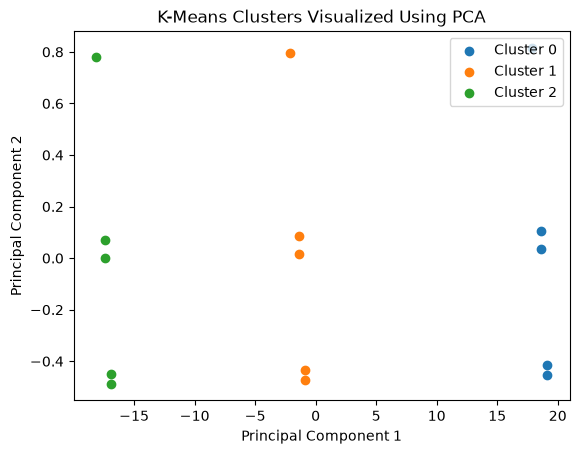

In [93]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Convert data into 2 dimensions for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# Plot each cluster using its assigned cluster ID
for cluster_id in range(3):
    points = [
        X_2d[i]
        for i in range(len(X_2d))
        if clusters[i] == cluster_id
    ]

    if points:
        plt.scatter(
            [p[0] for p in points],
            [p[1] for p in points],
            label=f"Cluster {cluster_id}"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.legend()
plt.show()
